In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/adult.csv')

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [6]:
df[df['workclass'] == '?'].info()

<class 'pandas.core.frame.DataFrame'>
Index: 1836 entries, 0 to 32544
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             1836 non-null   int64 
 1   workclass       1836 non-null   object
 2   fnlwgt          1836 non-null   int64 
 3   education       1836 non-null   object
 4   education.num   1836 non-null   int64 
 5   marital.status  1836 non-null   object
 6   occupation      1836 non-null   object
 7   relationship    1836 non-null   object
 8   race            1836 non-null   object
 9   sex             1836 non-null   object
 10  capital.gain    1836 non-null   int64 
 11  capital.loss    1836 non-null   int64 
 12  hours.per.week  1836 non-null   int64 
 13  native.country  1836 non-null   object
 14  income          1836 non-null   object
dtypes: int64(6), object(9)
memory usage: 229.5+ KB


In [7]:
df = df.replace("?", np.nan)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [9]:
df['workclass'].value_counts()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [10]:
df['occupation'].value_counts()

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

In [11]:
df['income'].value_counts()

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

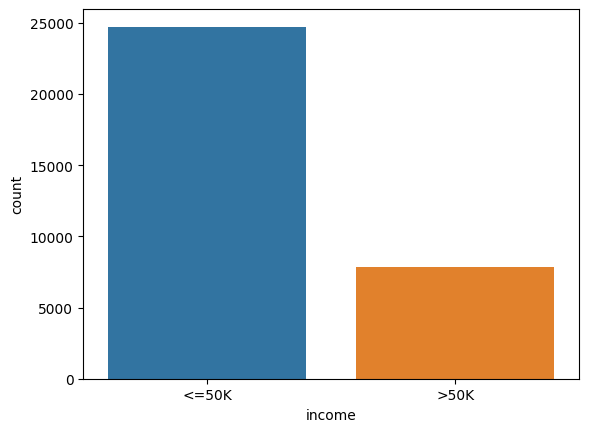

In [12]:
sns.countplot(data=df, x='income', hue='income');

In [13]:
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

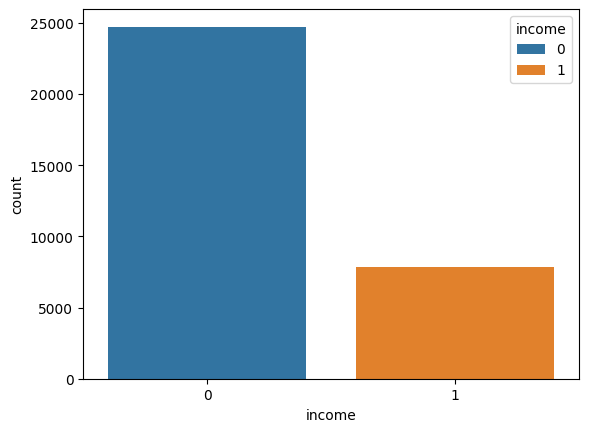

In [14]:
sns.countplot(data=df, x='income', hue='income');

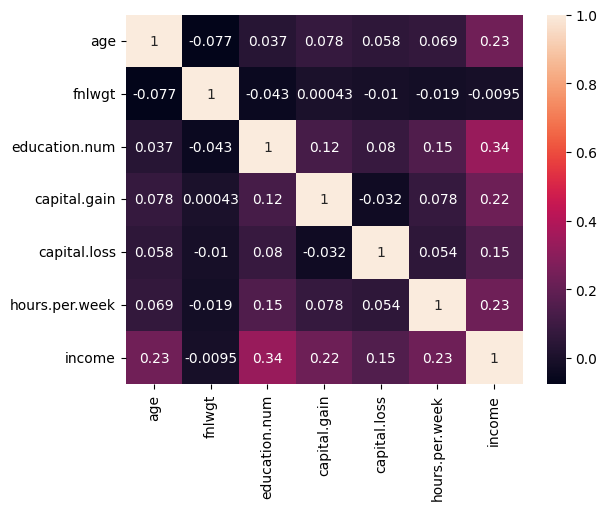

In [15]:
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest

In [17]:
X = df.drop('income', axis=1)

In [18]:
y = df['income']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104)

In [22]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [23]:
iso_forest = IsolationForest(contamination=0.01, n_estimators=100, n_jobs=-1, random_state=104)

In [25]:
mask = iso_forest.fit_predict(X_train[num_features])

In [26]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [27]:
X_train.shape

(26048, 14)

In [29]:
X_train_cleaned.shape

(25787, 14)

In [31]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('poly', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler())
])

In [33]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_transformer, cat_features),
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [35]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegressionCV(Cs=5,
                                   cv=5,
                                  penalty='l1',
                                  solver='liblinear',
                                  max_iter=10_000,
                                  n_jobs=-1,
                                  random_state=104,
                                   class_weight='balanced'))
])

In [36]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [37]:
%%time
pipe.fit(X_train_cleaned, y_train_cleaned)

CPU times: total: 7.23 s
Wall time: 22.5 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [38]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [39]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [1.]


In [40]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_pred_proba)
roc_auc_train = roc_auc_score(y_train, y_train_proba)

In [41]:
accuracy

0.8129894058037771

In [42]:
recall

0.8494484101232965

In [43]:
precision

0.5703703703703704

In [44]:
roc_auc_train

0.9138568543006966

In [45]:
roc_auc_test

0.912013440092552

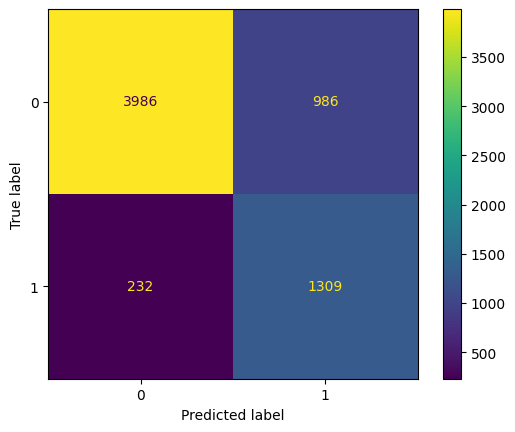

In [46]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test)

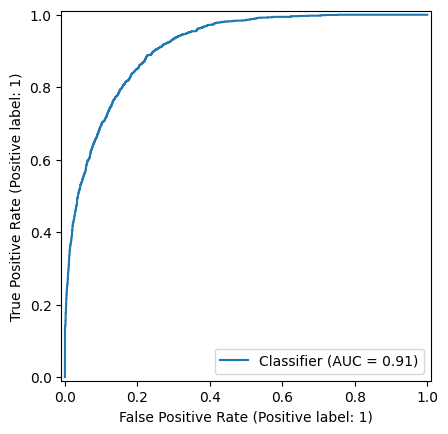

In [48]:
RocCurveDisplay.from_predictions(y_test, y_pred_proba);

In [60]:
%%time
pipe.fit(X, y)

CPU times: total: 9.86 s
Wall time: 39.3 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfor

In [71]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")

Лучшее значение C: [1.]


In [61]:
y_full_proba = pipe.predict_proba(X)[:, 1]

In [62]:
roc_auc_full = roc_auc_score(y, y_full_proba)

In [63]:
roc_auc_full

0.9133891963411972

In [64]:
census_test = {
    'age': [19, 48],
    'workclass': ['Private', 'Self-emp-inc'],
    'fnlwgt': [150_000, 150_000],
    'education': ['11th', 'Masters'],
    'education.num': [7, 14],
    'marital.status': ['Never-married', 'Married-civ-spouse'],
    'occupation': ['Other-service', 'Exec-managerial'],
    'relationship': ['Own-child', 'Husband'],
    'race': ['White', 'White'],
    'sex': ['Male', 'Male'],
    'capital.gain': [0, 99_999],
    'capital.loss': [0, 0],
    'hours.per.week': [20, 55],
    'native.country': ['United-States', 'United-States']
}

In [65]:
custom_census_df = pd.DataFrame(census_test)
custom_census_df.columns = X.columns

In [66]:
custom_census_df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,19,Private,150000,11th,7,Never-married,Other-service,Own-child,White,Male,0,0,20,United-States
1,48,Self-emp-inc,150000,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,55,United-States


In [80]:
preds = pipe.predict(custom_census_df)
preds_proba = pipe.predict_proba(custom_census_df)

In [68]:
print("="*90)
print("🇺🇸🗽 ДЕПЛОЙ СЛУЖБЫ АНАЛИЗА СОЦИАЛЬНО-ЭКОНОМИЧЕСКОГО ЦЕНЗА США")
print("="*90)

classes_map = {0: 'ДОХОД <=50K $ В ГОД (БАЗОВЫЙ КЛАСС) 📉', 1: 'ДОХОД >50K $ В ГОД (ВЫСШИЙ ЭЛИТНЫЙ КЛАСС) 💵🔥'}
expected_list = ["МОЛОДОЙ СТУДЕНТ БЕЗ ОБРАЗОВАНИЯ И КАПИТАЛА", "УСПЕШНЫЙ МАГИСТР-ТОП МЕНЕДЖЕР С ИНВЕСТИЦИЯМИ"]

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"👤 АНКЕТА АМЕРИКАНЦА №{idx+1}:")
    print(f"  -> Профиль анкеты:       {expected_list[idx]}")
    print(f"  -> Вердикт ИИ-модели:    {classes_map[class_out]}")
    print(f"  -> Уверенность логита:   {prob:.2f}% ✅")
    print("-" * 90)

🇺🇸🗽 ДЕПЛОЙ СЛУЖБЫ АНАЛИЗА СОЦИАЛЬНО-ЭКОНОМИЧЕСКОГО ЦЕНЗА США
👤 АНКЕТА АМЕРИКАНЦА №1:
  -> Профиль анкеты:       МОЛОДОЙ СТУДЕНТ БЕЗ ОБРАЗОВАНИЯ И КАПИТАЛА
  -> Вердикт ИИ-модели:    ДОХОД <=50K $ В ГОД (БАЗОВЫЙ КЛАСС) 📉
  -> Уверенность логита:   99.96% ✅
------------------------------------------------------------------------------------------
👤 АНКЕТА АМЕРИКАНЦА №2:
  -> Профиль анкеты:       УСПЕШНЫЙ МАГИСТР-ТОП МЕНЕДЖЕР С ИНВЕСТИЦИЯМИ
  -> Вердикт ИИ-модели:    ДОХОД >50K $ В ГОД (ВЫСШИЙ ЭЛИТНЫЙ КЛАСС) 💵🔥
  -> Уверенность логита:   100.00% ✅
------------------------------------------------------------------------------------------


In [69]:
class_percents = df['income'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 75.9%, 1: 24.1%


In [76]:
import json
import os

advanced_report = {
    "project": "Adult Census Income Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-08',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [74]:
from joblib import dump, load
import os

In [75]:
os.makedirs('model', exist_ok=True)

In [77]:
dump(pipe, "model/adult_census_income_predict_logistic_regression_cv_2026_v1.pkl")

['model/adult_census_income_predict_logistic_regression_cv_2026_v1.pkl']

In [78]:
loaded_pipe = load('model/adult_census_income_predict_logistic_regression_cv_2026_v1.pkl')

In [81]:
preds = loaded_pipe.predict(custom_census_df)
preds_proba = loaded_pipe.predict_proba(custom_census_df)

In [82]:
print("="*90)
print("🇺🇸🗽 ДЕПЛОЙ СЛУЖБЫ АНАЛИЗА СОЦИАЛЬНО-ЭКОНОМИЧЕСКОГО ЦЕНЗА США")
print("="*90)

classes_map = {0: 'ДОХОД <=50K $ В ГОД (БАЗОВЫЙ КЛАСС) 📉', 1: 'ДОХОД >50K $ В ГОД (ВЫСШИЙ ЭЛИТНЫЙ КЛАСС) 💵🔥'}
expected_list = ["МОЛОДОЙ СТУДЕНТ БЕЗ ОБРАЗОВАНИЯ И КАПИТАЛА", "УСПЕШНЫЙ МАГИСТР-ТОП МЕНЕДЖЕР С ИНВЕСТИЦИЯМИ"]

for idx in range(2):
    class_out = preds[idx]
    prob = preds_proba[idx][class_out] * 100
    
    print(f"👤 АНКЕТА АМЕРИКАНЦА №{idx+1}:")
    print(f"  -> Профиль анкеты:       {expected_list[idx]}")
    print(f"  -> Вердикт ИИ-модели:    {classes_map[class_out]}")
    print(f"  -> Уверенность логита:   {prob:.2f}% ✅")
    print("-" * 90)

🇺🇸🗽 ДЕПЛОЙ СЛУЖБЫ АНАЛИЗА СОЦИАЛЬНО-ЭКОНОМИЧЕСКОГО ЦЕНЗА США
👤 АНКЕТА АМЕРИКАНЦА №1:
  -> Профиль анкеты:       МОЛОДОЙ СТУДЕНТ БЕЗ ОБРАЗОВАНИЯ И КАПИТАЛА
  -> Вердикт ИИ-модели:    ДОХОД <=50K $ В ГОД (БАЗОВЫЙ КЛАСС) 📉
  -> Уверенность логита:   99.96% ✅
------------------------------------------------------------------------------------------
👤 АНКЕТА АМЕРИКАНЦА №2:
  -> Профиль анкеты:       УСПЕШНЫЙ МАГИСТР-ТОП МЕНЕДЖЕР С ИНВЕСТИЦИЯМИ
  -> Вердикт ИИ-модели:    ДОХОД >50K $ В ГОД (ВЫСШИЙ ЭЛИТНЫЙ КЛАСС) 💵🔥
  -> Уверенность логита:   100.00% ✅
------------------------------------------------------------------------------------------
